# Phân tích và dự báo nồng độ bụi mịn PM2.5 tại Hà Nội
Notebook trình bày toàn bộ quy trình Khoa học dữ liệu: **thu thập → tiền xử lý → EDA → mô hình hoá → đánh giá**.

Mã nguồn chi tiết nằm trong `src/`; notebook này gọi lại các bước và hiển thị kết quả.

In [1]:
import sys, pandas as pd
from IPython.display import Image, display
import os; os.chdir('..'); sys.path.insert(0, os.path.abspath('src'))

## 1. Thu thập dữ liệu
Nguồn: Open-Meteo Air Quality API (mô hình CAMS) và Historical Weather API (ERA5), theo giờ, toạ độ Hoàn Kiếm (21.03°N, 105.85°E), 08/2022 – 10/2026.

Bỏ comment dòng dưới để tải lại dữ liệu.

In [2]:
# !python src/collect_data.py
air = pd.read_csv('data/raw/air_quality_hourly.csv'); wea = pd.read_csv('data/raw/weather_hourly.csv')
print(air.shape, wea.shape); air.head()

(37272, 7) (37272, 10)


,time,pm2_5,pm10,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone
0,2022-08-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN
1,2022-08-01 01:00:00,NaN,NaN,NaN,NaN,NaN,NaN
2,2022-08-01 02:00:00,NaN,NaN,NaN,NaN,NaN,NaN
3,2022-08-01 03:00:00,NaN,NaN,NaN,NaN,NaN,NaN
4,2022-08-01 04:00:00,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Tiền xử lý & xây dựng đặc trưng

In [3]:
import preprocess; preprocess.main()

Số dòng sau khi ghép: 37272

Tỉ lệ thiếu trước xử lý (%):
pm2_5             0.21
pm10              0.21
co                0.21
no2               0.21
so2               0.21
o3                0.21
temp              0.00
humidity          0.00
dew_point         0.00
precipitation     0.00
pressure          0.00
cloud_cover       0.00
wind_speed        0.00
wind_dir          0.00
blh              11.72

Số dòng trùng thời gian bị loại: 0

Số ô còn thiếu sau xử lý: 0

Ngoại lai pm2_5: 289 giá trị > 147.7 đã được kẹp

Ngoại lai pm10: 175 giá trị > 183.3 đã được kẹp

Ngoại lai co: 927 giá trị > 1972.0 đã được kẹp

Ngoại lai no2: 210 giá trị > 107.8 đã được kẹp

Ngoại lai so2: 110 giá trị > 77.1 đã được kẹp

Ngoại lai o3: 41 giá trị > 304.0 đã được kẹp

Bảng ngày cuối cùng: 1545 ngày x 35 cột (2022-08-08 -> 2026-10-30)

Tỉ lệ ngày ô nhiễm (PM2.5 > 50): 33.9%


In [4]:
d = pd.read_csv('data/processed/daily_features.csv', parse_dates=['date'], index_col='date'); d.head()

,pm2_5,pm10,co,no2,so2,o3,temp,humidity,dew_point,pressure,...,pm2_5_lag1,pm2_5_lag2,pm2_5_lag3,pm2_5_lag7,pm2_5_roll3,pm2_5_roll7,pm2_5_diff1,rain_3d,target_pm25_next,target_polluted_next
date,,,,,,,,,,,,,,,,,,,,,
2022-08-08,25.625000,37.125000,376.000000,21.166667,8.379167,64.458333,27.137500,88.500000,24.983333,1002.933333,...,26.070833,28.566667,33.112500,45.765119,26.754167,36.075484,-0.445833,55.3,34.745833,0.0
2022-08-09,34.745833,50.158333,367.833333,18.666667,16.341667,75.833333,27.345833,86.625000,24.804167,1001.229167,...,25.625000,26.070833,28.566667,45.765119,28.813889,34.501301,9.120833,34.7,35.629167,0.0
2022-08-10,35.629167,51.179167,500.333333,28.175000,20.604167,40.375000,27.920833,85.708333,25.175000,998.683333,...,34.745833,25.625000,26.070833,45.765119,32.000000,33.053307,0.883333,34.5,19.625000,0.0
2022-08-11,19.625000,28.445833,402.125000,22.945833,16.675000,39.375000,25.950000,93.291667,24.779167,998.300000,...,35.629167,34.745833,25.625000,47.623151,30.000000,29.053571,-16.004167,97.6,27.187500,0.0
2022-08-12,27.187500,39.133333,464.500000,28.987500,21.475000,34.125000,25.091667,94.833333,24.179167,1003.745833,...,19.625000,35.629167,34.745833,33.112500,27.480556,28.207143,7.562500,125.3,51.091667,1.0


## 3. Phân tích khám phá (EDA)

In [5]:
import eda; eda.main()

THỐNG KÊ MÔ TẢ (dữ liệu ngày)
         pm2_5     pm10       co      no2     temp  humidity  precipitation  wind_speed      blh
count  1545.00  1545.00  1545.00  1545.00  1545.00   1545.00        1545.00     1545.00  1545.00
mean     45.23    55.96   690.18    27.48    24.60     79.08           6.34        9.02   452.80
std      20.33    24.54   242.96    10.56     4.77      9.80          12.96        3.35   132.25
min       0.91     1.29    60.00     0.00     9.22     36.04           0.00        3.06   150.62
25%      30.93    38.02   504.42    20.10    21.18     74.29           0.00        6.40   361.46
50%      40.54    51.32   645.25    25.78    25.98     81.42           0.70        8.50   450.63
75%      55.98    69.54   831.12    32.96    28.24     86.00           6.60       11.26   529.38
max     128.25   165.71  1558.21    76.47    33.03     96.46         133.00       35.37  1194.17

Độ lệch (skewness) PM2.5: 0.98

PM2.5 trung bình theo tháng:
month
1     53.2
2     41.5
3     4

### Chuỗi thời gian

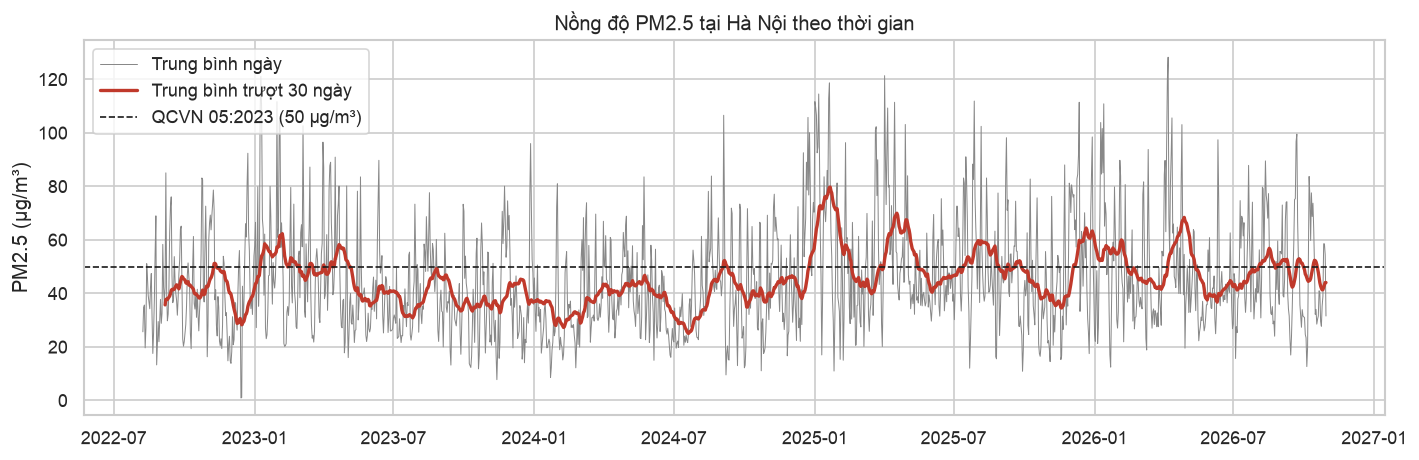

In [6]:
display(Image('figures/01_pm25_timeseries.png'))

### Phân phối & theo mùa

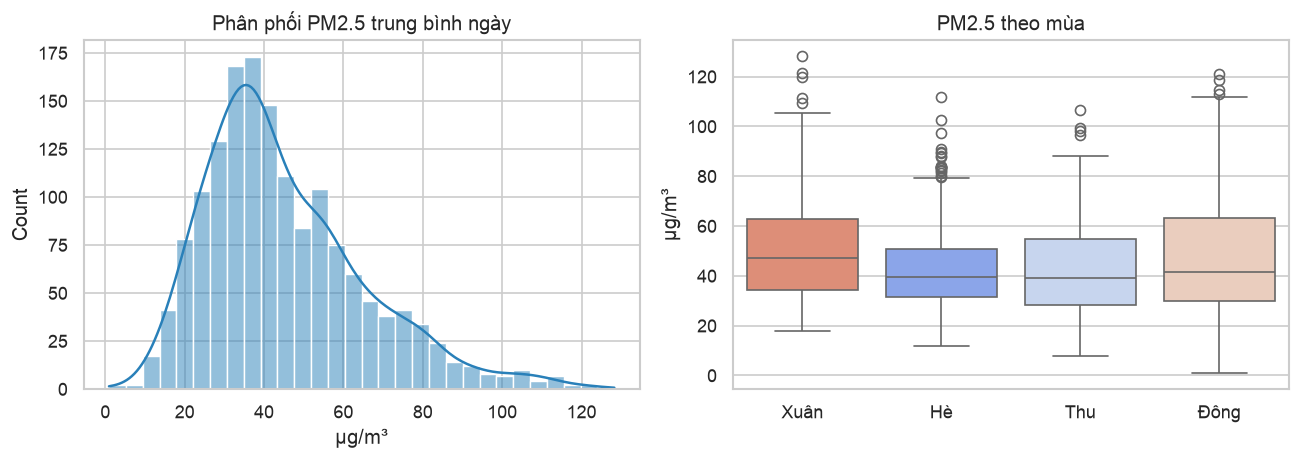

In [7]:
display(Image('figures/02_pm25_distribution_season.png'))

### Theo tháng & theo giờ

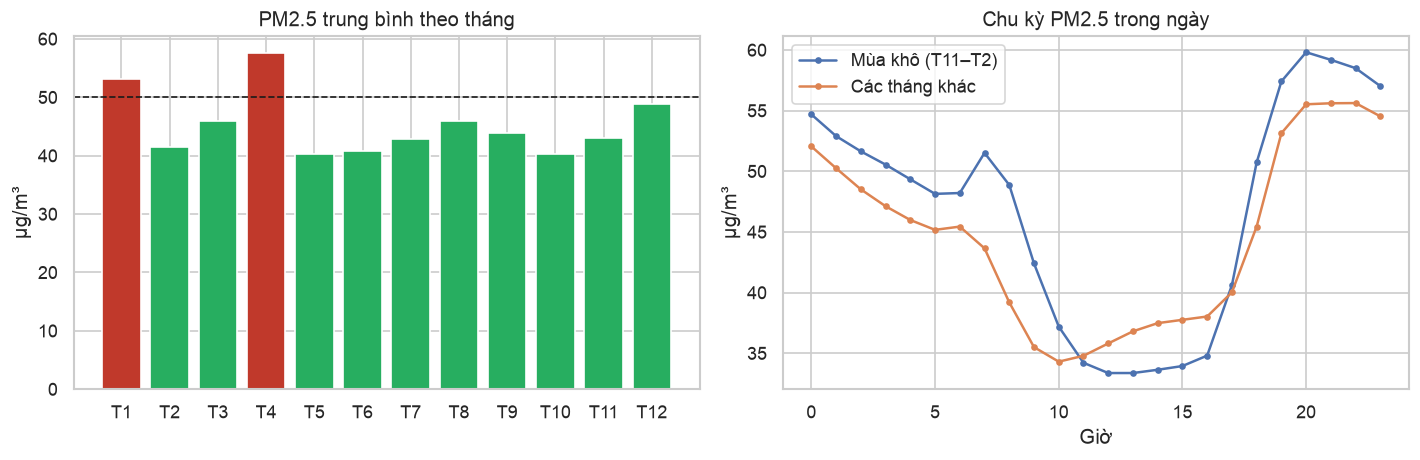

In [8]:
display(Image('figures/03_pm25_month_hour.png'))

### Heatmap năm × tháng

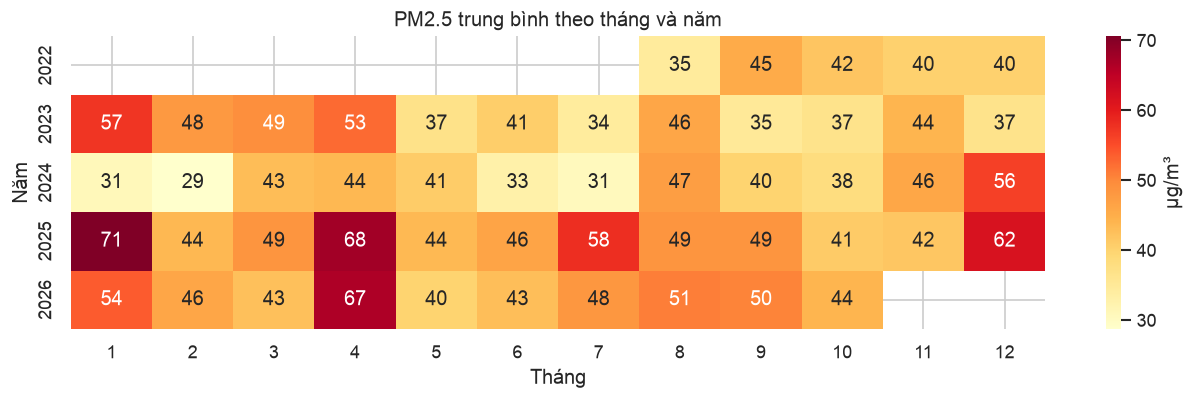

In [9]:
display(Image('figures/04_heatmap_year_month.png'))

### Tương quan

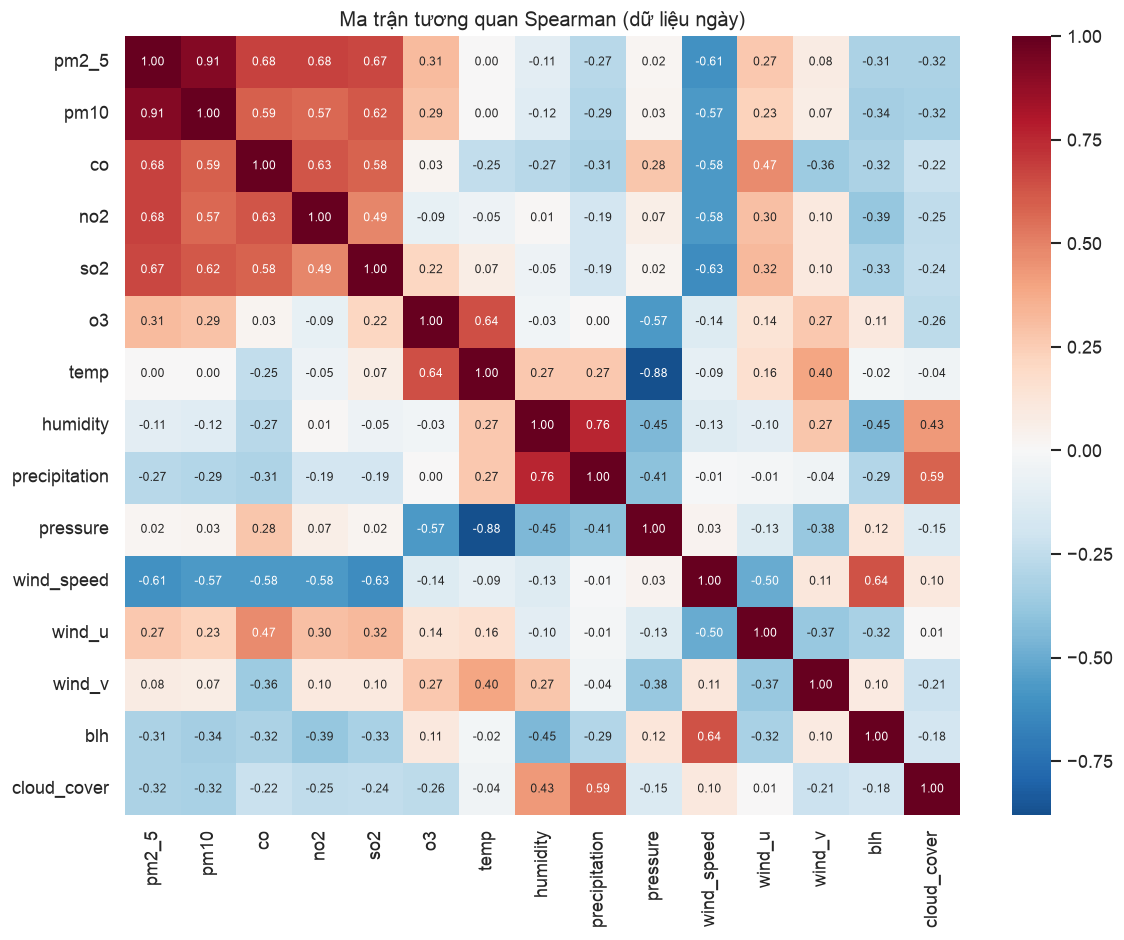

In [10]:
display(Image('figures/05_correlation.png'))

### PM2.5 và thời tiết

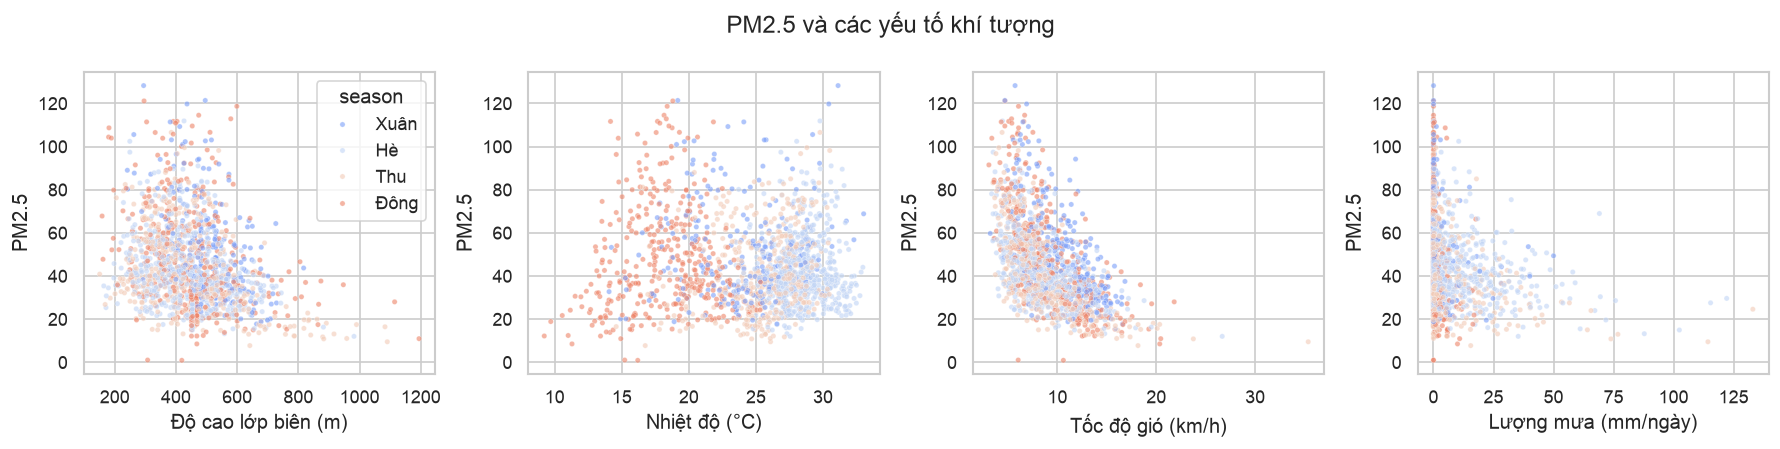

In [11]:
display(Image('figures/06_pm25_vs_weather.png'))

### Tự tương quan

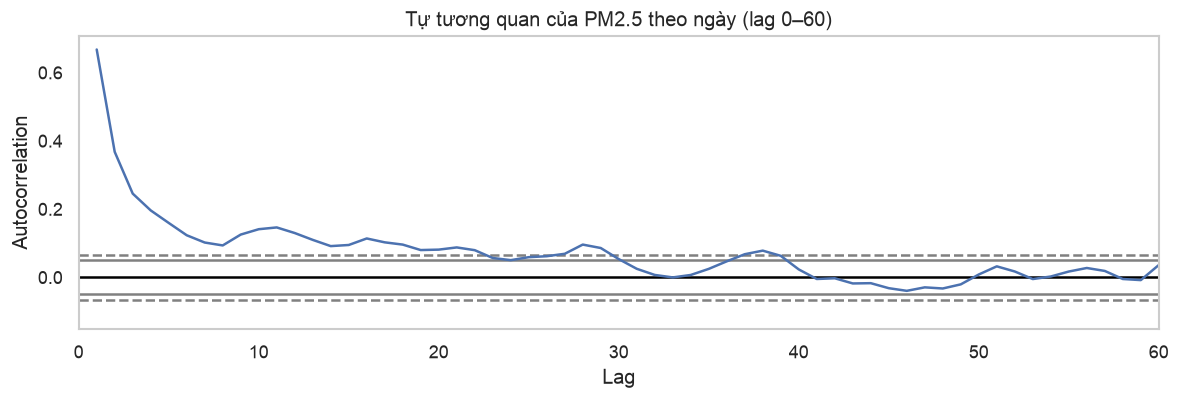

In [12]:
display(Image('figures/07_autocorrelation.png'))

## 4. Mô hình hoá
- **Hồi quy**: dự báo PM2.5 trung bình ngày mai
- **Phân loại**: ngày mai có vượt QCVN 05:2023 (50 µg/m³) không

Chia theo thời gian: train < 01/07/2025, test ≥ 01/07/2025; tinh chỉnh bằng TimeSeriesSplit 5 fold.

In [13]:
import train; train.main()

Train: 1058 ngày | Test: 487 ngày | 32 đặc trưng
Hồi quy...


  Ridge Regression: {'ridge__alpha': 100}


  Random Forest: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 300}


  Gradient Boosting: {'learning_rate': 0.03, 'max_depth': 3, 'max_iter': 200}


                      Mô hình    MAE   RMSE    R2
Baseline (ngày mai = hôm nay) 13.060 17.228 0.313
             Ridge Regression 11.365 14.623 0.505
                Random Forest 10.861 14.393 0.520
            Gradient Boosting 10.799 14.400 0.520
Phân loại...
  Logistic Regression: {'logisticregression__C': 0.1}


  Random Forest: {'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 300}


  Gradient Boosting: {'learning_rate': 0.03, 'max_depth': 3, 'max_iter': 200}


                      Mô hình  Accuracy  Precision  Recall    F1  ROC-AUC
Baseline (ngày mai = hôm nay)     0.754      0.704   0.704 0.704      NaN
          Logistic Regression     0.776      0.691   0.837 0.757    0.852
                Random Forest     0.778      0.713   0.783 0.746    0.847
            Gradient Boosting     0.774      0.688   0.837 0.756    0.848


In [14]:
display(pd.read_csv('report/results_regression.csv')); display(pd.read_csv('report/results_classification.csv'))

,Mô hình,MAE,RMSE,R2
0,Baseline (ngày mai = hôm nay),13.060,17.228,0.313
1,Ridge Regression,11.365,14.623,0.505
2,Random Forest,10.861,14.393,0.520
3,Gradient Boosting,10.799,14.400,0.520


,Mô hình,Accuracy,Precision,Recall,F1,ROC-AUC
0,Baseline (ngày mai = hôm nay),0.754,0.704,0.704,0.704,NaN
1,Logistic Regression,0.776,0.691,0.837,0.757,0.852
2,Random Forest,0.778,0.713,0.783,0.746,0.847
3,Gradient Boosting,0.774,0.688,0.837,0.756,0.848


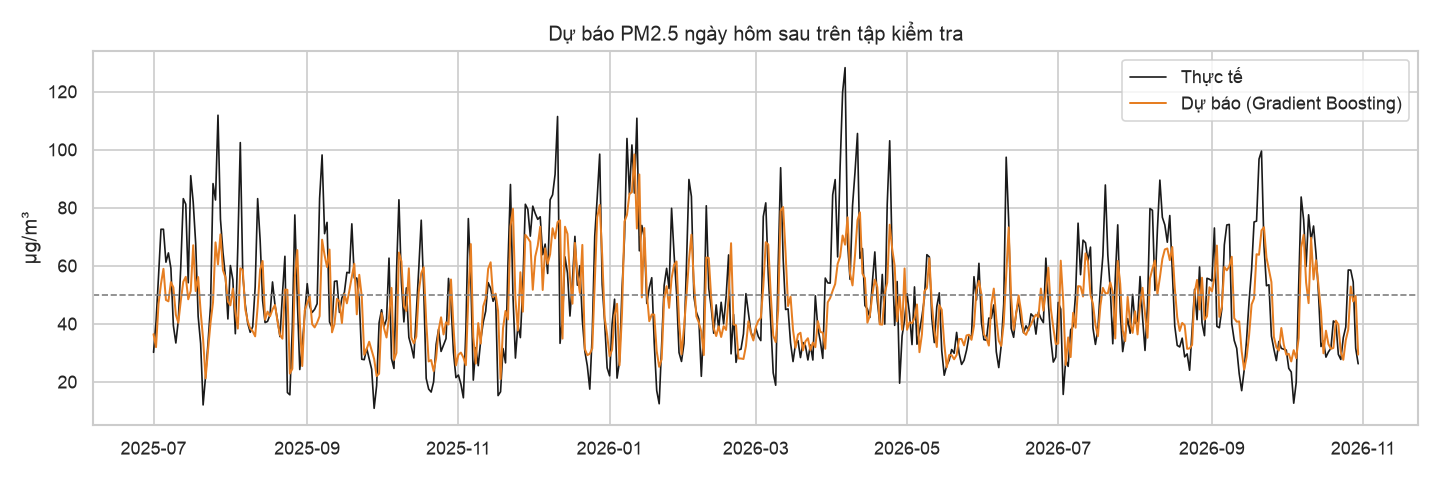

In [15]:
display(Image('figures/08_forecast_vs_actual.png'))

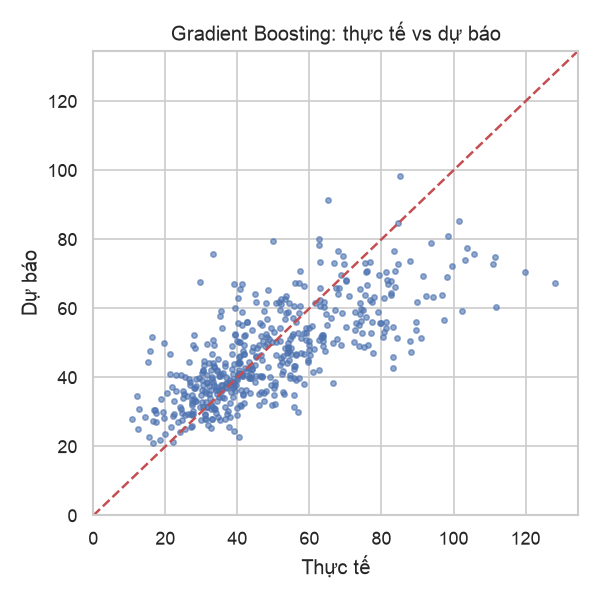

In [16]:
display(Image('figures/09_scatter_pred.png'))

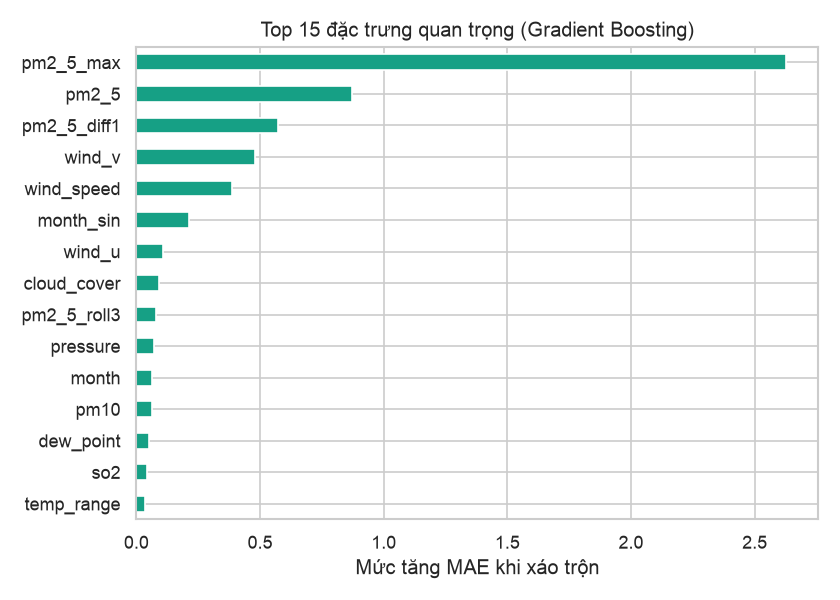

In [17]:
display(Image('figures/10_feature_importance.png'))

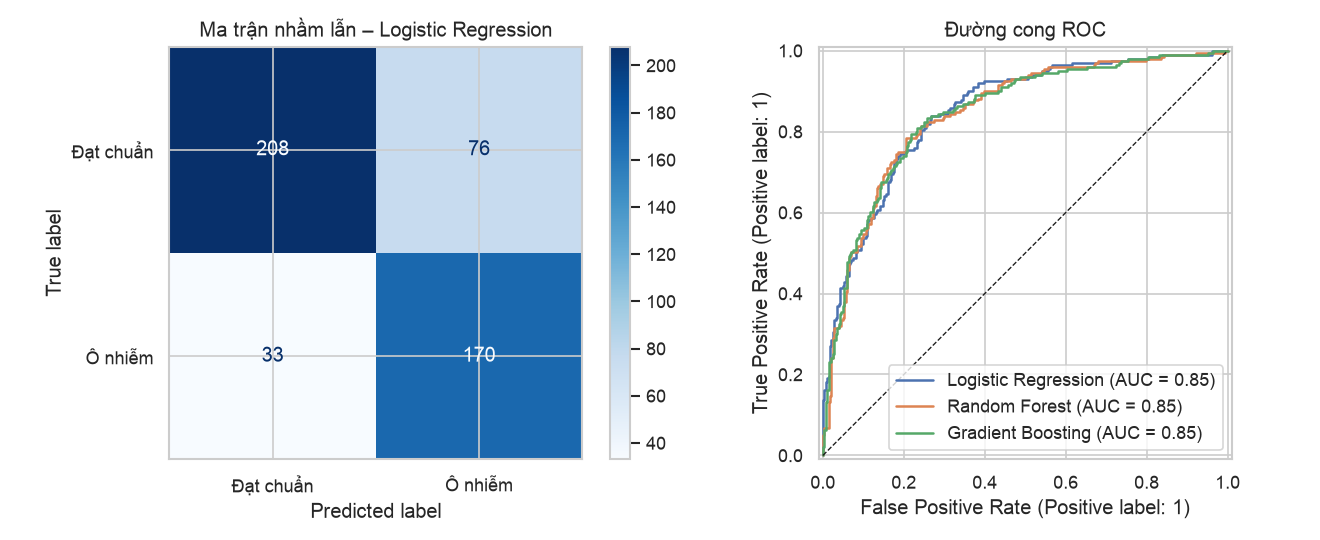

In [18]:
display(Image('figures/11_classification.png'))

## 5. Kết luận
Xem `report/BaoCao.md` để biết phần thảo luận, hạn chế và hướng phát triển.